In [1]:
import sys
sys.path.append("..")
import json
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from src.features import build_features, MODEL_B_DROP

In [2]:
test = pd.read_parquet("../data/processed/test.parquet")
model = xgb.XGBClassifier()
model.load_model("../models/xgb_model_b.json")
t = json.load(open("../models/thresholds.json"))["main_cost_1000"]

X = build_features(test)
feats = [c for c in X.columns if c not in MODEL_B_DROP]
X = X[feats]

test = test.assign(score=model.predict_proba(X)[:, 1])
test["alert"] = test["score"] >= t
print("Alerts:", test["alert"].sum(), "| frauds caught:", (test["alert"] & (test["isFraud"] == 1)).sum())

Alerts: 6178 | frauds caught: 553


In [3]:
booster = model.get_booster()
dm = xgb.DMatrix(X)
raw = booster.predict(dm, pred_contribs=True)

contrib = pd.DataFrame(raw[:, :-1], columns=feats, index=X.index)
base_value = raw[0, -1]

# Check: base value + contributions should equal the model's raw output
margin = booster.predict(dm, output_margin=True)
print("Max difference:", np.abs(contrib.sum(axis=1) + base_value - margin).max())

Max difference: 2.861023e-05


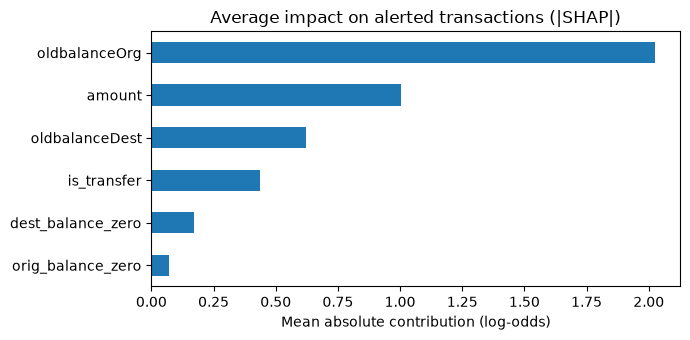

In [4]:
alerted = contrib[test["alert"]]
overall = alerted.abs().mean().sort_values()

overall.plot(kind="barh", figsize=(7, 3.5), title="Average impact on alerted transactions (|SHAP|)")
plt.xlabel("Mean absolute contribution (log-odds)")
plt.tight_layout()
plt.savefig("../reports/shap_alerts.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
is_fraud = test.loc[test["alert"], "isFraud"] == 1
comparison = pd.DataFrame({
    "caught_fraud": alerted[is_fraud].mean(),
    "false_alarm": alerted[~is_fraud].mean(),
})
comparison["difference"] = comparison["caught_fraud"] - comparison["false_alarm"]
comparison.sort_values("difference", ascending=False).round(3)

,caught_fraud,false_alarm,difference
oldbalanceOrg,3.700,1.828,1.872
amount,2.341,0.827,1.514
oldbalanceDest,1.470,0.334,1.136
is_transfer,0.637,0.168,0.469
dest_balance_zero,-0.001,-0.067,0.066
orig_balance_zero,0.026,0.029,-0.003


In [9]:
LABELS = {
    "dest_balance_zero": lambda r: "receiving account had zero balance" if r["oldbalanceDest"] == 0 else "receiving account had a balance",
    "is_transfer": lambda r: "payment type TRANSFER" if r["type"] == "TRANSFER" else "payment type CASH_OUT",
    "amount": lambda r: f"amount {r['amount']:,.0f}",
    "oldbalanceOrg": lambda r: f"sender balance {r['oldbalanceOrg']:,.0f}",
    "oldbalanceDest": lambda r: f"receiving balance {r['oldbalanceDest']:,.0f}",
    "orig_balance_zero": lambda r: "sender balance was zero" if r["oldbalanceOrg"] == 0 else "sender had funds",
}

def top_reasons(idx, n=3):
    c = contrib.loc[idx]
    top = c[c > 0].sort_values(ascending=False).head(n)
    row = test.loc[idx]
    return "; ".join(LABELS[f](row) for f in top.index)

queue = test[test["alert"]].sort_values("score", ascending=False).copy()
queue["reasons"] = [top_reasons(i) for i in queue.index]
queue[["type", "amount", "oldbalanceOrg", "oldbalanceDest", "score", "reasons", "isFraud"]].head(10)

,type,amount,oldbalanceOrg,oldbalanceDest,score,reasons,isFraud
5563708,CASH_OUT,10000000.00,10000000.00,109827.22,0.999686,"sender balance 10,000,000; amount 10,000,000; ...",1
5563736,CASH_OUT,6703831.40,6703831.40,99114.49,0.999686,"sender balance 6,703,831; amount 6,703,831; pa...",1
4967647,CASH_OUT,6721321.33,6721321.33,85644.25,0.999678,"sender balance 6,721,321; amount 6,721,321; pa...",1
5033183,CASH_OUT,10000000.00,10000000.00,350562.51,0.999662,"sender balance 10,000,000; amount 10,000,000; ...",1
5563756,CASH_OUT,9060955.18,9060955.18,271460.43,0.999653,"sender balance 9,060,955; amount 9,060,955; pa...",1
5188033,CASH_OUT,3244067.13,3244067.13,94273.57,0.999651,"sender balance 3,244,067; amount 3,244,067; pa...",1
5704596,CASH_OUT,9725837.08,9725837.08,160684.93,0.999641,"sender balance 9,725,837; amount 9,725,837; pa...",1
5072055,CASH_OUT,5338162.80,5338162.80,181895.58,0.999638,"sender balance 5,338,163; amount 5,338,163; pa...",1
5186080,CASH_OUT,3421212.04,3421212.04,57076.37,0.999633,"sender balance 3,421,212; amount 3,421,212; pa...",1
5188045,CASH_OUT,5807351.83,5807351.83,34380.89,0.999622,"sender balance 5,807,352; amount 5,807,352; pa...",1


In [10]:
example = pd.concat([
    queue[queue["isFraud"] == 1].head(3),
    queue[queue["isFraud"] == 0].head(3),
])[["type", "amount", "oldbalanceOrg", "oldbalanceDest", "score", "reasons", "isFraud"]]
example.to_csv("../reports/review_queue_example.csv")
example

,type,amount,oldbalanceOrg,oldbalanceDest,score,reasons,isFraud
5563708,CASH_OUT,10000000.00,10000000.00,109827.22,0.999686,"sender balance 10,000,000; amount 10,000,000; ...",1
5563736,CASH_OUT,6703831.40,6703831.40,99114.49,0.999686,"sender balance 6,703,831; amount 6,703,831; pa...",1
4967647,CASH_OUT,6721321.33,6721321.33,85644.25,0.999678,"sender balance 6,721,321; amount 6,721,321; pa...",1
5299617,TRANSFER,1888332.83,964862.00,0.00,0.912779,"sender balance 964,862; amount 1,888,333; rece...",0
5580880,TRANSFER,1984333.15,907493.00,0.00,0.912779,"sender balance 907,493; amount 1,984,333; rece...",0
5200969,TRANSFER,2511467.44,952964.00,0.00,0.908838,"sender balance 952,964; amount 2,511,467; rece...",0
